# Grammar Error Correction Project

Clean final notebook. Run cells from top to bottom. The Transformer section fine-tunes T5-small and the final comparison only uses metric files created by the evaluation cells in this notebook. Outputs are intentionally cleared so no stale metrics are shown.

In [9]:
# Install notebook dependencies
!pip install -q tf-keras transformers accelerate sentencepiece sacrebleu errant
!python -m spacy download en_core_web_sm -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 77.2 MB/s eta 0:00:0000:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [10]:
# Imports, configuration, and shared helpers
import os, sys, csv, json, time, math, random, platform, subprocess, re, gc, hashlib, zipfile, shutil
from pathlib import Path
from difflib import SequenceMatcher
from datetime import datetime, timezone
from IPython.display import display, FileLink

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import tensorflow as tf
import tf_keras as keras
from tf_keras import layers, mixed_precision
import sentencepiece as spm
from gensim.models import Word2Vec
from gensim.models.callbacks import CallbackAny2Vec
from tqdm.auto import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, roc_curve, fbeta_score
from nltk.translate.gleu_score import corpus_gleu
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
import torch
from torch.utils.data import Dataset
from transformers import T5ForConditionalGeneration, T5TokenizerFast, AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments

os.environ["WANDB_DISABLED"] = "true"
SEED = 42
OUT = Path("/kaggle/working")
OUT_DIR = OUT
C4_DIR = Path("/kaggle/input/datasets/dariocioni/c4200m")
PAD_ID = 0
DEFAULT_EVAL_N = 5000
NOTEBOOK_VERSION = "tweaked_2026_05_14"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2), encoding="utf-8")

def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def file_signature(path):
    path = Path(path)
    if not path.exists():
        return None
    stat = path.stat()
    return {"name": path.name, "size": int(stat.st_size), "mtime_ns": int(stat.st_mtime_ns)}

def data_signature():
    return {name: file_signature(OUT / f"{name}.parquet") for name in ["train", "val", "test"]}

def token_edit(a, b):
    sm = SequenceMatcher(None, str(a).split(), str(b).split())
    return sum(max(i2 - i1, j2 - j1) for tag, i1, i2, j1, j2 in sm.get_opcodes() if tag != "equal")

def masked_loss(y_true, y_pred):
    loss = keras.losses.sparse_categorical_crossentropy(tf.cast(y_true, tf.int32), y_pred, from_logits=True)
    mask = tf.cast(tf.not_equal(tf.cast(y_true, tf.int32), PAD_ID), loss.dtype)
    return tf.reduce_sum(loss * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)

def masked_acc(y_true, y_pred):
    pred = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
    y_true = tf.cast(y_true, tf.int32)
    mask = tf.cast(tf.not_equal(y_true, PAD_ID), tf.float32)
    correct = tf.cast(tf.equal(pred, y_true), tf.float32)
    return tf.reduce_sum(correct * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)

def save_history(history, json_name, loss_png, acc_png, title):
    hist = {k: [float(x) for x in v] for k, v in history.history.items()}
    save_json(hist, OUT / json_name)
    epochs = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(9, 4))
    plt.plot(epochs, hist["loss"], label="train")
    plt.plot(epochs, hist["val_loss"], label="val")
    plt.title(f"{title} loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT / loss_png, dpi=120, bbox_inches="tight"); plt.show()

    acc_key = "masked_acc" if "masked_acc" in hist else "accuracy"
    val_acc_key = "val_masked_acc" if "val_masked_acc" in hist else "val_accuracy"
    if acc_key in hist and val_acc_key in hist:
        plt.figure(figsize=(9, 4))
        plt.plot(epochs, hist[acc_key], label="train")
        plt.plot(epochs, hist[val_acc_key], label="val")
        plt.title(f"{title} token accuracy")
        plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=0.3)
        plt.tight_layout(); plt.savefig(OUT / acc_png, dpi=120, bbox_inches="tight"); plt.show()

    print(f"Saved history and curves for {title}")
    return hist

def get_eval_sample_indices(test_len, n_eval=DEFAULT_EVAL_N, seed=SEED):
    n_eval = min(int(n_eval), int(test_len))
    path = OUT / "eval_sample_idx.npy"
    if path.exists():
        idx = np.load(path)
        if len(idx) == n_eval and len(np.unique(idx)) == n_eval and idx.max(initial=-1) < test_len:
            return idx.astype(int)
    rng = np.random.RandomState(seed)
    idx = rng.choice(test_len, n_eval, replace=False).astype(int)
    np.save(path, idx)
    return idx

def sample_hash(sample_idx):
    return hashlib.md5(np.asarray(sample_idx, dtype=np.int64).tobytes()).hexdigest()

def ids_to_text(ids_2d, processor, eos_id, pad_id=0, bos_id=None):
    texts = []
    for row in ids_2d:
        toks = []
        for tok in row:
            tok = int(tok)
            if tok == eos_id:
                break
            if tok == pad_id or (bos_id is not None and tok == bos_id):
                continue
            toks.append(tok)
        texts.append(processor.decode(toks))
    return texts

# ---------------------------------------------------------------------------
# F0.5 via ERRANT (lazy-loaded). Falls back to a simple word-level Levenshtein
# edit alignment if ERRANT or spaCy is unavailable.
# ---------------------------------------------------------------------------
_ERRANT = {"loaded": False, "annotator": None, "error": None}

def _try_load_errant():
    if _ERRANT["loaded"]:
        return _ERRANT["annotator"]
    try:
        import errant
        _ERRANT["annotator"] = errant.load("en")
    except Exception as exc:
        _ERRANT["annotator"] = None
        _ERRANT["error"] = repr(exc)
    _ERRANT["loaded"] = True
    return _ERRANT["annotator"]

def _edits_from_errant(annotator, src, target):
    src_doc = annotator.parse(str(src))
    tgt_doc = annotator.parse(str(target))
    edits = annotator.annotate(src_doc, tgt_doc)
    out = []
    for e in edits:
        if e.type == "noop":
            continue
        # Use the original-side span as the edit "key" (insertion/deletion-aware).
        out.append((int(e.o_start), int(e.o_end), str(e.c_str).strip()))
    return out

def _word_align_edits(src, target):
    s = str(src).split()
    t = str(target).split()
    sm = SequenceMatcher(a=s, b=t, autojunk=False)
    edits = []
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag == "equal":
            continue
        edits.append((i1, i2, " ".join(t[j1:j2])))
    return edits

def compute_fbeta_edit_metrics(src_strs, tgt_strs, pred_strs, beta=0.5):
    """Edit-level P/R/F-beta. Uses ERRANT if available, else a word-level
    Levenshtein aligner. Returns dict with keys P, R, F{beta}, n_gold,
    n_pred, n_tp, edit_extractor.
    """
    annotator = _try_load_errant()
    use_errant = annotator is not None
    extractor = "errant" if use_errant else "levenshtein"
    tp = fp = fn = 0
    for src, tgt, pred in zip(src_strs, tgt_strs, pred_strs):
        if use_errant:
            try:
                gold = set(_edits_from_errant(annotator, src, tgt))
                guess = set(_edits_from_errant(annotator, src, pred))
            except Exception:
                gold = set(_word_align_edits(src, tgt))
                guess = set(_word_align_edits(src, pred))
                extractor = "levenshtein_fallback"
        else:
            gold = set(_word_align_edits(src, tgt))
            guess = set(_word_align_edits(src, pred))
        tp += len(gold & guess)
        fp += len(guess - gold)
        fn += len(gold - guess)
    P = tp / max(tp + fp, 1)
    R = tp / max(tp + fn, 1)
    if (beta * beta * P + R) > 0:
        Fb = (1 + beta * beta) * P * R / (beta * beta * P + R)
    else:
        Fb = 0.0
    return {
        f"precision_edit": float(P),
        f"recall_edit": float(R),
        f"f{beta:g}_edit": float(Fb),
        "n_gold_edits": int(tp + fn),
        "n_pred_edits": int(tp + fp),
        "n_tp_edits": int(tp),
        "edit_extractor": extractor,
    }

def evaluate_predictions(model_name, src_strs, tgt_strs, pred_strs, out_json, out_csv, sample_idx=None, extra=None, compute_f05=True):
    src_toks = [str(s).split() for s in src_strs]
    tgt_toks = [str(t).split() for t in tgt_strs]
    pred_toks = [str(p).split() for p in pred_strs]

    gleu_pred = corpus_gleu([[t] for t in tgt_toks], pred_toks)
    gleu_src = corpus_gleu([[t] for t in tgt_toks], src_toks)
    bleu_pred = corpus_bleu([[t] for t in tgt_toks], pred_toks, smoothing_function=SmoothingFunction().method1)
    exact = np.mean([str(p).strip() == str(t).strip() for p, t in zip(pred_strs, tgt_strs)])
    ed_src = np.mean([token_edit(s, t) for s, t in zip(src_strs, tgt_strs)])
    ed_pred = np.mean([token_edit(p, t) for p, t in zip(pred_strs, tgt_strs)])

    rows = []
    for s, t, p in zip(src_strs, tgt_strs, pred_strs):
        d_src = token_edit(s, t)
        d_pred = token_edit(p, t)
        if str(p).strip() == str(t).strip():
            category = "perfect"
        elif str(p).strip() == str(s).strip():
            category = "unchanged"
        elif d_pred < d_src:
            category = "improved"
        else:
            category = "harm"
        rows.append((s, t, p, category, d_src, d_pred))

    examples = pd.DataFrame(rows, columns=["src", "tgt", "pred", "category", "edit_src_to_tgt", "edit_pred_to_tgt"])
    examples.to_csv(OUT / out_csv, index=False)

    metrics = {
        "model": model_name,
        "notebook_version": NOTEBOOK_VERSION,
        "n_eval": int(len(src_strs)),
        "sample_hash": sample_hash(sample_idx) if sample_idx is not None else None,
        "gleu_src_baseline": float(gleu_src),
        "gleu_pred": float(gleu_pred),
        "bleu_pred": float(bleu_pred),
        "exact_match": float(exact),
        "edit_src": float(ed_src),
        "edit_pred": float(ed_pred),
        "edit_reduction_pct": float((ed_src - ed_pred) / ed_src * 100) if ed_src else 0.0,
        "perfect_pct": float((examples["category"] == "perfect").mean() * 100),
        "improved_pct": float((examples["category"] == "improved").mean() * 100),
        "unchanged_pct": float((examples["category"] == "unchanged").mean() * 100),
        "harm_pct": float((examples["category"] == "harm").mean() * 100),
        "helpful_pct": float(((examples["category"] == "perfect") | (examples["category"] == "improved")).mean() * 100),
    }

    if compute_f05:
        f05 = compute_fbeta_edit_metrics(src_strs, tgt_strs, pred_strs, beta=0.5)
        metrics.update(f05)

    if extra:
        metrics.update(extra)
    save_json(metrics, OUT / out_json)

    f05_disp = metrics.get("f0.5_edit")
    f05_str = f" | F0.5={f05_disp*100:.2f}%" if f05_disp is not None else ""
    print(f"{model_name} on {len(src_strs):,} test examples")
    print(f"GLEU={gleu_pred:.4f} | BLEU={bleu_pred:.4f} | exact={exact*100:.2f}% | helpful={metrics['helpful_pct']:.1f}% | harm={metrics['harm_pct']:.1f}%{f05_str}")
    print("Behaviour (%):")
    print(examples["category"].value_counts(normalize=True).mul(100).round(1).to_string())
    print(f"Saved: {out_json}, {out_csv}")
    return metrics, examples

def require_c4_shards():
    files = sorted(C4_DIR.glob("C4_200M.tsv-*"))
    if files:
        return files

    input_root = Path("/kaggle/input")
    if input_root.exists():
        files = sorted(input_root.rglob("C4_200M.tsv-*"))
        if files:
            print(f"Auto-discovered C4 shards under: {files[0].parent}")
            return files

    raise FileNotFoundError(
        f"No C4_200M.tsv-* shards found under {C4_DIR} or /kaggle/input. "
        "Attach the C4_200M Kaggle dataset before running this notebook."
    )


In [11]:
# Environment and dataset check
print(f"Python: {sys.version.split()[0]}")
print(f"Platform: {platform.platform()}")
print(f"TensorFlow: {tf.__version__}")
print(f"tf_keras: {getattr(keras, '__version__', 'unknown')}")
print(f"Torch: {torch.__version__}")

gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow GPUs: {len(gpus)}")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

try:
    smi = subprocess.check_output([
        "nvidia-smi",
        "--query-gpu=index,name,memory.total,memory.free,driver_version",
        "--format=csv,noheader",
    ], text=True)
    print(smi.strip())
except Exception as exc:
    print(f"nvidia-smi unavailable: {exc}")

subprocess.run(["df", "-h", str(OUT)], check=False)
files = require_c4_shards()
print(f"C4 shards found: {len(files)}")
for path in files[:10]:
    print(f"{path.name}: {path.stat().st_size / 1e9:.2f} GB")

Python: 3.12.12
Platform: Linux-6.6.122+-x86_64-with-glibc2.35
TensorFlow: 2.19.0
tf_keras: 2.19.0
Torch: 2.10.0+cu128
TensorFlow GPUs: 2
0, Tesla T4, 15360 MiB, 14910 MiB, 580.105.08
1, Tesla T4, 15360 MiB, 14910 MiB, 580.105.08
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop1       20G  514M   20G   3% /kaggle/working
C4 shards found: 10
C4_200M.tsv-00000-of-00010: 4.94 GB
C4_200M.tsv-00001-of-00010: 4.94 GB
C4_200M.tsv-00002-of-00010: 4.94 GB
C4_200M.tsv-00003-of-00010: 4.94 GB
C4_200M.tsv-00004-of-00010: 4.94 GB
C4_200M.tsv-00005-of-00010: 4.94 GB
C4_200M.tsv-00006-of-00010: 4.94 GB
C4_200M.tsv-00007-of-00010: 4.94 GB
C4_200M.tsv-00008-of-00010: 4.93 GB
C4_200M.tsv-00009-of-00010: 4.94 GB


## Data Preparation

In [12]:
# Inspect C4_200M file format

files = require_c4_shards()

print(f"Shards: {len(files)}")
for f in files:
    print(f"  {f.name}  {f.stat().st_size/1e9:.2f} GB")

print("\nFirst 3 parsed rows:")
with open(files[0], "r", encoding="utf-8", errors="replace") as fh:
    reader = csv.reader(fh, delimiter="\t", quoting=csv.QUOTE_NONE)
    for i, row in enumerate(reader):
        print(f"[{i}] ({len(row)} cols)")
        for j, c in enumerate(row):
            print(f"   col{j}: {c[:200]!r}")
        if i >= 2: break

print("\nLine count of shard 1:")
print(subprocess.run(["wc", "-l", str(files[0])], capture_output=True, text=True).stdout.strip())

print("\nLength stats on 100k lines (col0 vs col1):")
c0_lens, c1_lens, diff, n = [], [], 0, 0
with open(files[0], "r", encoding="utf-8", errors="replace") as fh:
    for line in fh:
        cols = line.rstrip("\n").split("\t")
        if len(cols) >= 2:
            c0_lens.append(len(cols[0].split()))
            c1_lens.append(len(cols[1].split()))
            if cols[0] != cols[1]: diff += 1
        n += 1
        if n >= 100_000: break

c0, c1 = np.array(c0_lens), np.array(c1_lens)
print(f"  pairs scanned : {n:,}")
print(f"  pairs differ  : {diff:,} ({diff/n*100:.1f}%)")
print(f"  col0 words    : mean={c0.mean():.1f}  median={np.median(c0):.0f}  p95={np.percentile(c0,95):.0f}  max={c0.max()}")
print(f"  col1 words    : mean={c1.mean():.1f}  median={np.median(c1):.0f}  p95={np.percentile(c1,95):.0f}  max={c1.max()}")
print(f"  mean diff     : {c0.mean()-c1.mean():+.2f}")


Shards: 10
  C4_200M.tsv-00000-of-00010  4.94 GB
  C4_200M.tsv-00001-of-00010  4.94 GB
  C4_200M.tsv-00002-of-00010  4.94 GB
  C4_200M.tsv-00003-of-00010  4.94 GB
  C4_200M.tsv-00004-of-00010  4.94 GB
  C4_200M.tsv-00005-of-00010  4.94 GB
  C4_200M.tsv-00006-of-00010  4.94 GB
  C4_200M.tsv-00007-of-00010  4.94 GB
  C4_200M.tsv-00008-of-00010  4.93 GB
  C4_200M.tsv-00009-of-00010  4.94 GB

First 3 parsed rows:
[0] (2 cols)
   col0: 'Bitcoin is for $7,094 this morning, which CoinDesk says.'
   col1: 'Bitcoin goes for $7,094 this morning, according to CoinDesk.'
[1] (2 cols)
   col0: 'The effect of widespread dud targets two face up attack position monsters on the field.'
   col1: '1. The effect of "widespread dud" targets two face up attack position monsters on the field.'
[2] (2 cols)
   col0: 'tax on sales of stores for non residents are set at 21% for 2014 and 20% in 2015 payable on sales tentatively earned from the difference of the property value some time of purchase (price differe

In [13]:
# Sample 1.2M pairs from C4_200M across all 10 shards

files = require_c4_shards()

PER_SHARD = 120_000           # 120k × 10 shards = 1.2M (>1M minimum)
MIN_W, MAX_W = 4, 50          # length filter: covers >95% of pairs (p95 was 51)

src_all, tgt_all = [], []
stats = {"scanned": 0, "kept": 0, "drop_identical": 0, "drop_length": 0, "drop_format": 0}
t0 = time.time()

for i, fpath in enumerate(files):
    kept = 0
    with open(fpath, "r", encoding="utf-8", errors="replace") as fh:
        for line in fh:
            stats["scanned"] += 1
            cols = line.rstrip("\r\n").split("\t")     # files use \r\n line endings
            if len(cols) != 2:
                stats["drop_format"] += 1; continue
            src, tgt = cols[0].strip(), cols[1].strip()
            # drop identical pairs (col0 == col1) — they teach the model nothing
            if not src or not tgt or src == tgt:
                stats["drop_identical"] += 1; continue
            ls, lt = len(src.split()), len(tgt.split())
            if not (MIN_W <= ls <= MAX_W and MIN_W <= lt <= MAX_W):
                stats["drop_length"] += 1; continue
            src_all.append(src); tgt_all.append(tgt)
            kept += 1; stats["kept"] += 1
            if kept >= PER_SHARD:
                break
    print(f"Shard {i}: kept {kept:,}  total: {stats['kept']:,}  elapsed {time.time()-t0:.0f}s")

print("\nFilter stats:")
for k, v in stats.items():
    print(f"  {k:18s} {v:,}")

df = pd.DataFrame({"src": src_all, "tgt": tgt_all})
if len(df) < 1_000_000:
    raise RuntimeError(f"Sample contains fewer than 1,000,000 pairs: {len(df):,}. Check C4 shards and filters.")
parquet_path = OUT_DIR / "c4_gec_sample.parquet"
df.to_parquet(parquet_path, index=False)

meta = {"n_pairs": len(df), "min_words": MIN_W, "max_words": MAX_W,
        "shards_used": [f.name for f in files], "filter_stats": stats}
(OUT_DIR / "c4_gec_meta.json").write_text(json.dumps(meta, indent=2))

print(f"\nSaved {parquet_path}  ({parquet_path.stat().st_size/1e6:.1f} MB)")
print(f"Pairs: {len(df):,}")
print("\nFirst 3 rows:")
print(df.head(3).to_string())


Shard 0: kept 120,000  total: 120,000  elapsed 1s
Shard 1: kept 120,000  total: 240,000  elapsed 2s
Shard 2: kept 120,000  total: 360,000  elapsed 2s
Shard 3: kept 120,000  total: 480,000  elapsed 3s
Shard 4: kept 120,000  total: 600,000  elapsed 4s
Shard 5: kept 120,000  total: 720,000  elapsed 5s
Shard 6: kept 120,000  total: 840,000  elapsed 5s
Shard 7: kept 120,000  total: 960,000  elapsed 6s
Shard 8: kept 120,000  total: 1,080,000  elapsed 7s
Shard 9: kept 120,000  total: 1,200,000  elapsed 8s

Filter stats:
  scanned            1,282,266
  kept               1,200,000
  drop_identical     7,590
  drop_length        74,676
  drop_format        0

Saved /kaggle/working/c4_gec_sample.parquet  (207.7 MB)
Pairs: 1,200,000

First 3 rows:
                                                                                       src                                                                                           tgt
0                                 Bitcoin is for $7,094 this mornin

Loaded 1,200,000 pairs
train: 1,150,000   val: 25,000   test: 25,000


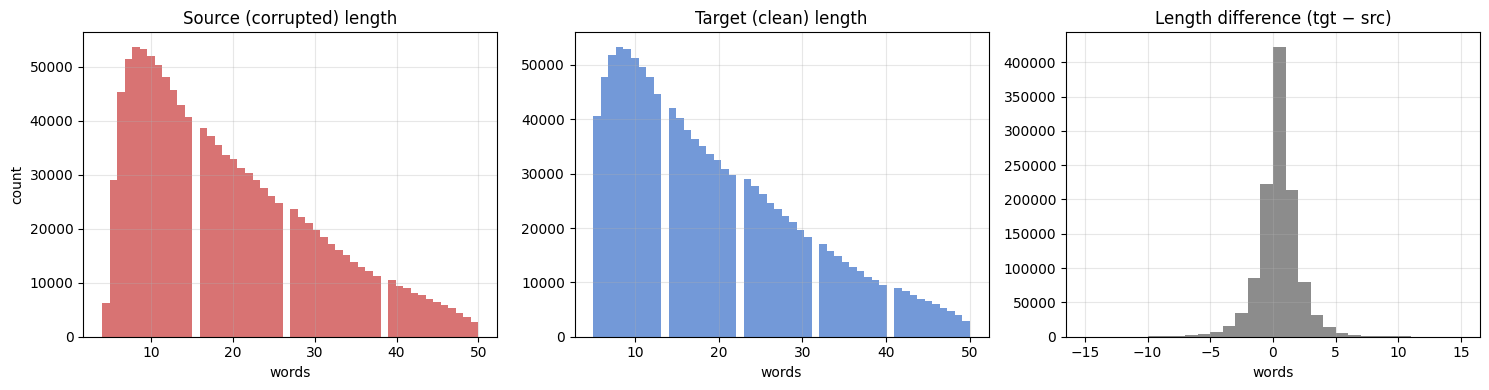

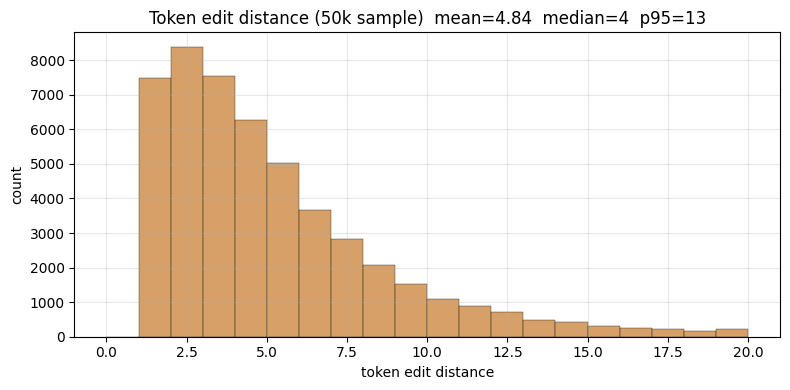


src words : mean=19.34  median=17  p95=41  max=50
tgt words : mean=19.30  median=17  p95=41  max=50
edits     : mean=4.84  median=4  p95=13  max=69
pairs identical at token level: 0.00%

Saved: train/val/test parquet, 01_length_distributions.png, 02_edit_distance.png, eda_stats.json


In [14]:
# Train/val/test split + EDA on the 1.2M pairs

df = pd.read_parquet(OUT / "c4_gec_sample.parquet")
print(f"Loaded {len(df):,} pairs")

# 1.15M / 25k / 25k split
rng = np.random.default_rng(42)
idx = rng.permutation(len(df))
val_n = test_n = 25_000
train_idx, val_idx, test_idx = idx[:-2*val_n], idx[-2*val_n:-val_n], idx[-val_n:]
train, val, test = (df.iloc[ix].reset_index(drop=True) for ix in (train_idx, val_idx, test_idx))
train.to_parquet(OUT/"train.parquet", index=False)
val.to_parquet(OUT/"val.parquet", index=False)
test.to_parquet(OUT/"test.parquet", index=False)
print(f"train: {len(train):,}   val: {len(val):,}   test: {len(test):,}")

# Length stats on full train set
src_lens = train["src"].str.split().str.len().to_numpy()
tgt_lens = train["tgt"].str.split().str.len().to_numpy()
diff = tgt_lens - src_lens

# Token-level edit distance on 50k subsample (full set is too slow for SequenceMatcher)
def token_edit(a, b):
    sm = SequenceMatcher(None, a.split(), b.split())
    return sum(max(i2-i1, j2-j1) for tag, i1, i2, j1, j2 in sm.get_opcodes() if tag != "equal")

sub = train.sample(50_000, random_state=42)
edits = np.array([token_edit(s, t) for s, t in zip(sub["src"], sub["tgt"])])

# Length distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(src_lens, bins=50, color="#cc4444", alpha=0.75); axes[0].set_title("Source (corrupted) length"); axes[0].set_xlabel("words"); axes[0].set_ylabel("count"); axes[0].grid(alpha=0.3)
axes[1].hist(tgt_lens, bins=50, color="#4477cc", alpha=0.75); axes[1].set_title("Target (clean) length"); axes[1].set_xlabel("words"); axes[1].grid(alpha=0.3)
axes[2].hist(diff, bins=range(-15, 16), color="#666666", alpha=0.75); axes[2].set_title("Length difference (tgt − src)"); axes[2].set_xlabel("words"); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT/"01_length_distributions.png", dpi=120, bbox_inches="tight"); plt.show()

# Edit distance distribution
plt.figure(figsize=(8, 4))
plt.hist(edits, bins=range(0, 21), color="#cc8844", alpha=0.8, edgecolor="black", linewidth=0.3)
plt.xlabel("token edit distance"); plt.ylabel("count")
plt.title(f"Token edit distance (50k sample)  mean={edits.mean():.2f}  median={int(np.median(edits))}  p95={int(np.percentile(edits,95))}")
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(OUT/"02_edit_distance.png", dpi=120, bbox_inches="tight"); plt.show()

# Numeric summary
print(f"\nsrc words : mean={src_lens.mean():.2f}  median={np.median(src_lens):.0f}  p95={np.percentile(src_lens,95):.0f}  max={src_lens.max()}")
print(f"tgt words : mean={tgt_lens.mean():.2f}  median={np.median(tgt_lens):.0f}  p95={np.percentile(tgt_lens,95):.0f}  max={tgt_lens.max()}")
print(f"edits     : mean={edits.mean():.2f}  median={int(np.median(edits))}  p95={int(np.percentile(edits,95))}  max={edits.max()}")
print(f"pairs identical at token level: {(edits==0).sum()/len(edits)*100:.2f}%")

eda = {"src_len_mean": float(src_lens.mean()), "src_len_p95": int(np.percentile(src_lens,95)),
       "tgt_len_mean": float(tgt_lens.mean()), "tgt_len_p95": int(np.percentile(tgt_lens,95)),
       "edit_mean": float(edits.mean()), "edit_median": int(np.median(edits)),
       "edit_p95": int(np.percentile(edits,95)),
       "edit_zero_pct": float((edits==0).sum()/len(edits)*100)}
(OUT/"eda_stats.json").write_text(json.dumps(eda, indent=2))
print("\nSaved: train/val/test parquet, 01_length_distributions.png, 02_edit_distance.png, eda_stats.json")


## Model 1: BoW Detection Baseline

Vocab size: 100,000   train matrix: (2300000, 100000)
train  acc=0.6446  P=0.6581  R=0.6019  F1=0.6288  F0.5=0.6460  AUC=0.6999
val    acc=0.6286  P=0.6396  R=0.5893  F1=0.6134  F0.5=0.6288  AUC=0.6781
test   acc=0.6278  P=0.6384  R=0.5897  F1=0.6131  F0.5=0.6280  AUC=0.6792


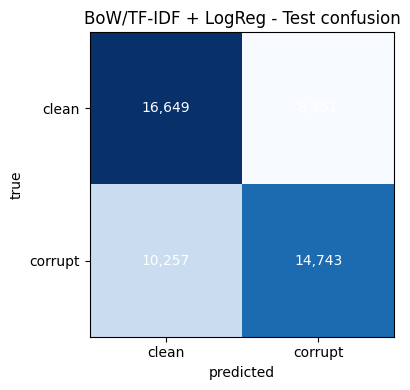

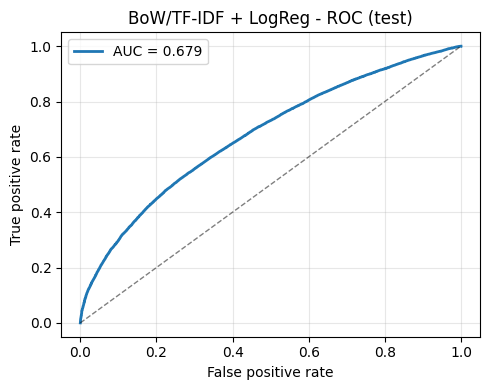


Top 10 features pushing -> CORRUPTED:
  33387                          +21.803
  wo                             +11.146
  of                             +9.830
  thier                          +9.141
  informations                   +8.725
  staffs                         +8.646
  safty                          +8.466
  thes                           +7.725
  datas                          +7.674
  to                             +7.530

Top 10 features pushing -> CLEAN:
  according to                   -8.341
  has viewed                     -8.234
  vote giving                    -7.303
  rights reserved                -6.212
  relating to                    -5.845
  the same                       -5.461
  bookmark the                   -4.963
  viewed by                      -4.859
  consist of                     -4.479
  depending on                   -4.423

Test pairs both classified correctly : 7,115/25,000  (28.5%)
Corruption missed (false negative)   : 10,257/25,000  (41.0%)


In [15]:
# Model 1 - Stronger BoW baseline: error detection using TF-IDF bigrams + Logistic Regression

train = pd.read_parquet(OUT/"train.parquet")
val   = pd.read_parquet(OUT/"val.parquet")
test  = pd.read_parquet(OUT/"test.parquet")

# src=1 means grammatically corrupted/noisy, tgt=0 means corrected/clean.
N_PAIRS = len(train)
rng = np.random.default_rng(0)
sub = train.iloc[rng.choice(len(train), N_PAIRS, replace=False)].reset_index(drop=True)

X_tr_text = list(sub["src"]) + list(sub["tgt"]);   y_tr = np.array([1]*N_PAIRS + [0]*N_PAIRS)
X_va_text = list(val["src"]) + list(val["tgt"]);   y_va = np.array([1]*len(val) + [0]*len(val))
X_te_text = list(test["src"]) + list(test["tgt"]); y_te = np.array([1]*len(test) + [0]*len(test))

vec = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=100_000,
    min_df=3,
    sublinear_tf=True,
)
Xtr = vec.fit_transform(X_tr_text)
Xva = vec.transform(X_va_text)
Xte = vec.transform(X_te_text)
print(f"Vocab size: {len(vec.vocabulary_):,}   train matrix: {Xtr.shape}")

clf = LogisticRegression(C=2.0, max_iter=1000, solver="saga", n_jobs=-1, verbose=0)
clf.fit(Xtr, y_tr)

def report(X, y):
    yp = clf.predict(X)
    yprob = clf.predict_proba(X)[:, 1]
    pr, rc, f1, _ = precision_recall_fscore_support(y, yp, average="binary")
    return {
        "acc": float(accuracy_score(y, yp)),
        "P": float(pr),
        "R": float(rc),
        "F1": float(f1),
        "F05": float(fbeta_score(y, yp, beta=0.5)),
        "AUC": float(roc_auc_score(y, yprob)),
    }

m_tr, m_va, m_te = report(Xtr, y_tr), report(Xva, y_va), report(Xte, y_te)
for n, m in [("train", m_tr), ("val", m_va), ("test", m_te)]:
    print(f"{n:5s}  acc={m['acc']:.4f}  P={m['P']:.4f}  R={m['R']:.4f}  F1={m['F1']:.4f}  F0.5={m['F05']:.4f}  AUC={m['AUC']:.4f}")

# Confusion matrix on test
yp = clf.predict(Xte)
cm = confusion_matrix(y_te, yp)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["clean", "corrupt"]); ax.set_yticklabels(["clean", "corrupt"])
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("BoW/TF-IDF + LogReg - Test confusion")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout(); plt.savefig(OUT/"03_bow_confusion.png", dpi=120, bbox_inches="tight"); plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_te, clf.predict_proba(Xte)[:, 1])
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {m_te['AUC']:.3f}")
plt.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("BoW/TF-IDF + LogReg - ROC (test)"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT/"04_bow_roc.png", dpi=120, bbox_inches="tight"); plt.show()

coef = clf.coef_.ravel()
inv = {v: k for k, v in vec.vocabulary_.items()}
print("\nTop 10 features pushing -> CORRUPTED:")
for i in np.argsort(coef)[-10:][::-1]: print(f"  {inv[i]:30s} {coef[i]:+.3f}")
print("\nTop 10 features pushing -> CLEAN:")
for i in np.argsort(coef)[:10]:        print(f"  {inv[i]:30s} {coef[i]:+.3f}")

src_pred = clf.predict(vec.transform(test["src"]))
tgt_pred = clf.predict(vec.transform(test["tgt"]))
both_ok  = np.where((src_pred == 1) & (tgt_pred == 0))[0]
missed   = np.where(src_pred == 0)[0]
falarm   = np.where(tgt_pred == 1)[0]

print(f"\nTest pairs both classified correctly : {len(both_ok):,}/{len(test):,}  ({len(both_ok)/len(test)*100:.1f}%)")
print(f"Corruption missed (false negative)   : {len(missed):,}/{len(test):,}  ({len(missed)/len(test)*100:.1f}%)")
print(f"Clean wrongly flagged (false positive): {len(falarm):,}/{len(test):,}  ({len(falarm)/len(test)*100:.1f}%)")

print("\n--- 3 successful detections ---")
for i in both_ok[:3]:
    print(f"  CORRUPT: {test['src'].iloc[i]}\n  CLEAN  : {test['tgt'].iloc[i]}\n")
print("--- 3 missed corruptions (BoW cannot model order/context well enough) ---")
for i in missed[:3]:
    print(f"  CORRUPT but predicted CLEAN: {test['src'].iloc[i]}\n  Actual clean version       : {test['tgt'].iloc[i]}\n")

json.dump({"train": m_tr, "val": m_va, "test": m_te, "vocab": len(vec.vocabulary_),
           "n_train_sentences": int(len(y_tr)), "representation": "TF-IDF unigram+bigram"},
          open(OUT/"bow_metrics.json", "w"), indent=2)
joblib.dump(clf, OUT/"bow_clf.joblib"); joblib.dump(vec, OUT/"bow_vec.joblib")
print("\nSaved: 03_bow_confusion.png, 04_bow_roc.png, bow_metrics.json, bow_clf.joblib, bow_vec.joblib")


## Shared Tokenization for LSTM Models

In [16]:
# Tokenization (SentencePiece BPE) + Word2Vec embeddings shared by Models 2-3
# The pretrained T5 model in Model 4 uses its own tokenizer.

train = pd.read_parquet(OUT/"train.parquet")
val   = pd.read_parquet(OUT/"val.parquet")
test  = pd.read_parquet(OUT/"test.parquet")

VOCAB_SIZE = 16_000
MAX_LEN    = 72
EMB_DIM    = 128

# 1. Write SPM training corpus
corpus = OUT/"spm_corpus.txt"
sample = train.sample( len(train), random_state=42)
with open(corpus, "w", encoding="utf-8") as fh:
    for s, t in tqdm(zip(sample["src"], sample["tgt"]), total=len(sample), desc="Writing SPM corpus"):
        fh.write(str(s) + "\n"); fh.write(str(t) + "\n")

# 2. Train SentencePiece BPE
print("\nTraining SentencePiece BPE...")
t0 = time.time()
spm.SentencePieceTrainer.train(
    input=str(corpus), model_prefix=str(OUT/"spm"),
    vocab_size=VOCAB_SIZE, model_type="bpe", character_coverage=1.0,
    pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    pad_piece="<pad>", unk_piece="<unk>", bos_piece="<s>", eos_piece="</s>",
    input_sentence_size=1_000_000, shuffle_input_sentence=True, num_threads=4)
print(f"  done in {time.time()-t0:.0f}s")
sp = spm.SentencePieceProcessor(model_file=str(OUT/"spm.model"))
print(f"BPE vocab: {sp.get_piece_size()}")
print("Sample:", sp.encode("This is a test sentence with a typo: spelinng.", out_type=str))

# 3. Encode all splits
def enc_src(s):
    return sp.encode(str(s), out_type=int)[:MAX_LEN]

def enc_tgt(s):
    ids = sp.encode(str(s), out_type=int)[:MAX_LEN-2]
    return [sp.bos_id()] + ids + [sp.eos_id()]

def pad(seqs, L):
    arr = np.zeros((len(seqs), L), dtype=np.int32)
    for i, s in enumerate(seqs):
        arr[i, :min(len(s), L)] = s[:L]
    return arr

def encode_split(name, src_series, tgt_series):
    src = [enc_src(s) for s in tqdm(src_series, desc=f"{name} src", leave=False)]
    tgt = [enc_tgt(s) for s in tqdm(tgt_series, desc=f"{name} tgt", leave=False)]
    return pad(src, MAX_LEN), pad(tgt, MAX_LEN)

X_tr, Y_tr = encode_split("train", train["src"], train["tgt"])
X_va, Y_va = encode_split("val",   val["src"],   val["tgt"])
X_te, Y_te = encode_split("test",  test["src"],  test["tgt"])
np.savez(OUT/"tokenized.npz", X_tr=X_tr, Y_tr=Y_tr, X_va=X_va, Y_va=Y_va, X_te=X_te, Y_te=Y_te)
print(f"X_tr={X_tr.shape}  Y_tr={Y_tr.shape}   file: {(OUT/'tokenized.npz').stat().st_size/1e6:.0f} MB")

true_lens = (X_tr != 0).sum(axis=1)
print(f"Encoded src length: mean={true_lens.mean():.1f}  p95={np.percentile(true_lens,95):.0f}  max={true_lens.max()}")

# 4. Train Word2Vec on SentencePiece tokens for LSTM initialization
print("\nBuilding Word2Vec sentence list...")
w2v_sents = [sp.encode(str(s), out_type=str) for s in tqdm(train["src"], desc="W2V tokenize")]

class EpochLogger(CallbackAny2Vec):
    def __init__(self): self.epoch = 0
    def on_epoch_begin(self, model): self.t_epoch = time.time()
    def on_epoch_end(self, model):
        self.epoch += 1
        print(f"  W2V epoch {self.epoch} done — {time.time()-self.t_epoch:.0f}s")

print("\nTraining Word2Vec (CBOW, 4 epochs)...")
w2v = Word2Vec(w2v_sents, vector_size=EMB_DIM, window=5, min_count=1,
               workers=4, sg=0, epochs=4, seed=42, compute_loss=False,
               callbacks=[EpochLogger()])
print(f"Word2Vec vocab: {len(w2v.wv)}")

emb = np.random.normal(0, 0.1, (sp.get_piece_size(), EMB_DIM)).astype(np.float32)
emb[0] = 0.0
covered = 0
for pid in tqdm(range(sp.get_piece_size()), desc="Building embedding matrix"):
    piece = sp.id_to_piece(pid)
    if piece in w2v.wv:
        emb[pid] = w2v.wv[piece]; covered += 1
print(f"Word2Vec coverage: {covered}/{sp.get_piece_size()} ({covered/sp.get_piece_size()*100:.1f}%)")
np.save(OUT/"w2v_embedding.npy", emb)

print("Saved: spm.model, spm.vocab, tokenized.npz, w2v_embedding.npy")


Writing SPM corpus:   0%|          | 0/500000 [00:00<?, ?it/s]


Training SentencePiece BPE...
  done in 62s
BPE vocab: 16000
Sample: ['▁This', '▁is', '▁a', '▁test', '▁sentence', '▁with', '▁a', '▁typ', 'o', ':', '▁sp', 'el', 'in', 'ng', '.']


train src:   0%|          | 0/1150000 [00:00<?, ?it/s]

train tgt:   0%|          | 0/1150000 [00:00<?, ?it/s]

val src:   0%|          | 0/25000 [00:00<?, ?it/s]

...

X_tr=(1150000, 72)  Y_tr=(1150000, 72)   file: 691 MB
Encoded src length: mean=28.4  p95=60  max=72

Building Word2Vec sentence list...


W2V tokenize:   0%|          | 0/1150000 [00:00<?, ?it/s]


Training Word2Vec (CBOW, 4 epochs)...
  W2V epoch 1 done — 22s
  W2V epoch 2 done — 22s
  W2V epoch 3 done — 22s
  W2V epoch 4 done — 22s
Word2Vec vocab: 16946


Building embedding matrix:   0%|          | 0/16000 [00:00<?, ?it/s]

Word2Vec coverage: 15949/16000 (99.7%)
Saved: spm.model, spm.vocab, tokenized.npz, w2v_embedding.npy


## Model 2: LSTM without Attention

INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPUs will likely run quickly with dtype policy mixed_float16 as they all have compute capability of at least 7.0


INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPUs will likely run quickly with dtype policy mixed_float16 as they all have compute capability of at least 7.0


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')


I0000 00:00:1778777371.578569      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1778777371.584769      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')


GPUs: 2 | global batch: 256
Model: "lstm_no_attention_gec"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 dec_in (InputLayer)         [(None, 71)]                 0         []                            
                                                                                                  
 enc_in (InputLayer)         [(None, 72)]                 0         []                            
                                                                                                  
 spm_w2v_embedding (Embeddi  multiple                     2048000   ['enc_in[0][0]',              
 ng)                                                                 'dec_in[0][0]']              
                                                                                                  
 spatial_dropout1d (Spatial  (None, 72, 128)      

...

4493/4493 [==============================] - ETA: 0s - loss: 5.4278 - masked_acc: 0.2107INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


4493/4493 [==============================] - 1059s 230ms/step - loss: 5.4278 - masked_acc: 0.2107 - val_loss: 4.5020 - val_masked_acc: 0.2893 - lr: 3.0000e-04
Epoch 2/8
4493/4493 [==============================] - 959s 213ms/step - loss: 4.3926 - masked_acc: 0.2981 - val_loss: 3.9443 - val_masked_acc: 0.3445 - lr: 3.0000e-04
Epoch 3/8
4493/4493 [==============================] - 958s 213ms/step - loss: 4.0010 - masked_acc: 0.3361 - val_loss: 3.6145 - val_masked_acc: 0.3808 - lr: 3.0000e-04
Epoch 4/8
4493/4493 [==============================] - 955s 213ms/step - loss: 3.7413 - masked_acc: 0.3631 - val_loss: 3.3768 - val_masked_acc: 0.4089 - lr: 3.0000e-04
Epoch 5/8
4493/4493 [==============================] - 956s 213ms/step - loss: 3.5481 - masked_acc: 0.3844 - val_loss: 3.2006 - val_masked_acc: 0.4303 - lr: 3.0000e-04
Epoch 6/8
4493/4493 [==============================] - 955s 212ms/step - loss: 3.3959 - masked_acc: 0.4021 - val_loss: 3.0660 - val_masked_acc: 0.4478 - lr: 3.0000e-04
E

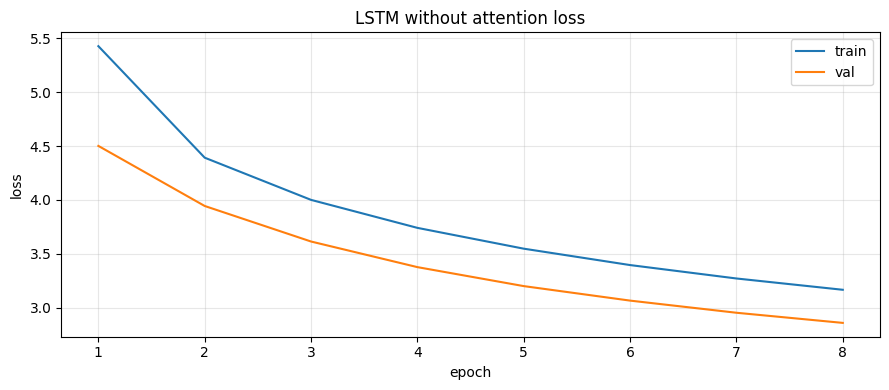

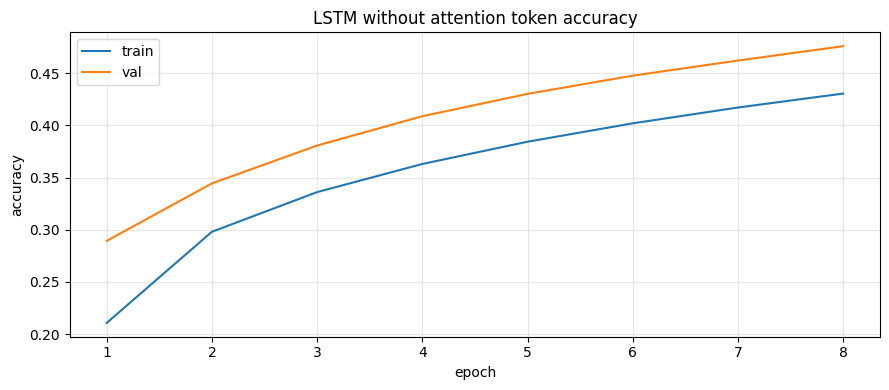

Saved history and curves for LSTM without attention
Saved: lstm_noatt_best.keras, lstm_noatt_final.keras, lstm_noatt_history.json


In [17]:
# Model 2 - LSTM seq2seq WITHOUT attention (tweaked: biLSTM encoder)

keras.backend.clear_session()
mixed_precision.set_global_policy("mixed_float16")

data = np.load(OUT/"tokenized.npz")
X_tr, Y_tr = data["X_tr"], data["Y_tr"]
X_va, Y_va = data["X_va"], data["Y_va"]
w2v_emb = np.load(OUT/"w2v_embedding.npy").astype("float32")

VOCAB_SIZE, EMB_DIM = w2v_emb.shape
MAX_LEN = X_tr.shape[1]
PAD_ID = 0
HIDDEN = 512
DROPOUT = 0.20
EPOCHS = 8

tr_inputs = {"enc_in": X_tr, "dec_in": Y_tr[:, :-1]}
tr_target = Y_tr[:, 1:]
va_inputs = {"enc_in": X_va, "dec_in": Y_va[:, :-1]}
va_target = Y_va[:, 1:]

strategy = tf.distribute.MirroredStrategy()
N_GPU = strategy.num_replicas_in_sync
PER_REPLICA_BATCH = 128
GLOBAL_BATCH = PER_REPLICA_BATCH * N_GPU
print(f"GPUs: {N_GPU} | global batch: {GLOBAL_BATCH}")

with strategy.scope():
    def masked_loss(y_true, y_pred):
        loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred, from_logits=True)
        mask = tf.cast(y_true != PAD_ID, loss.dtype)
        return tf.reduce_sum(loss * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)

    def masked_acc(y_true, y_pred):
        pred = tf.cast(tf.argmax(y_pred, axis=-1), y_true.dtype)
        correct = tf.cast(pred == y_true, tf.float32)
        mask = tf.cast(y_true != PAD_ID, tf.float32)
        return tf.reduce_sum(correct * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)

    enc_in = keras.Input(shape=(MAX_LEN,), dtype="int32", name="enc_in")
    dec_in = keras.Input(shape=(MAX_LEN-1,), dtype="int32", name="dec_in")

    emb_layer = layers.Embedding(
        VOCAB_SIZE, EMB_DIM,
        weights=[w2v_emb],
        mask_zero=True,
        trainable=True,
        name="spm_w2v_embedding",
    )

    enc_emb = layers.SpatialDropout1D(DROPOUT)(emb_layer(enc_in))
    # BiLSTM encoder. HIDDEN total = 512 (256 forward + 256 backward).
    enc_outs = layers.Bidirectional(
        layers.LSTM(HIDDEN // 2, return_sequences=False, return_state=True,
                    dropout=DROPOUT, recurrent_dropout=0.0),
        name="encoder_bilstm",
    )(enc_emb)
    _, fwd_h, fwd_c, bwd_h, bwd_c = enc_outs
    state_h = layers.Concatenate(name="state_h_concat")([fwd_h, bwd_h])
    state_c = layers.Concatenate(name="state_c_concat")([fwd_c, bwd_c])

    dec_emb = layers.SpatialDropout1D(DROPOUT)(emb_layer(dec_in))
    dec_seq = layers.LSTM(
        HIDDEN, return_sequences=True, dropout=DROPOUT, recurrent_dropout=0.0,
        name="decoder_lstm",
    )(dec_emb, initial_state=[state_h, state_c])

    logits = layers.Dense(VOCAB_SIZE, dtype="float32", name="vocab_logits")(dec_seq)
    model_lstm_noatt = keras.Model({"enc_in": enc_in, "dec_in": dec_in}, logits, name="lstm_no_attention_gec")

    opt = keras.optimizers.Adam(learning_rate=3e-4, clipnorm=1.0)
    model_lstm_noatt.compile(optimizer=opt, loss=masked_loss, metrics=[masked_acc])

model_lstm_noatt.summary()

callbacks = [
    keras.callbacks.ModelCheckpoint(str(OUT/"lstm_noatt_best.keras"), monitor="val_masked_acc", mode="max", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_masked_acc", mode="max", patience=2, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=5e-5, verbose=1),
]

t0 = time.time()
hist_noatt = model_lstm_noatt.fit(
    tr_inputs, tr_target,
    validation_data=(va_inputs, va_target),
    epochs=EPOCHS,
    batch_size=GLOBAL_BATCH,
    callbacks=callbacks,
    verbose=1,
)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

model_lstm_noatt.save(OUT/"lstm_noatt_final.keras")
hist_noatt_clean = save_history(
    hist_noatt,
    "lstm_noatt_history.json",
    "05_lstm_noatt_loss.png",
    "05_lstm_noatt_acc.png",
    "LSTM without attention",
)
print("Saved: lstm_noatt_best.keras, lstm_noatt_final.keras, lstm_noatt_history.json")

In [18]:
# Model 2 evaluation: LSTM without attention
sp = spm.SentencePieceProcessor(model_file=str(OUT / "spm.model"))
test = pd.read_parquet(OUT / "test.parquet")
data = np.load(OUT / "tokenized.npz")
X_te = data["X_te"].astype("int32")
MAX_LEN = X_te.shape[1]
BOS, EOS, PAD = sp.bos_id(), sp.eos_id(), 0

try:
    model_lstm_noatt
except NameError:
    model_lstm_noatt = keras.models.load_model(
        str(OUT / "lstm_noatt_best.keras"),
        custom_objects={"masked_loss": masked_loss, "masked_acc": masked_acc},
        safe_mode=False,
    )

@tf.function(reduce_retracing=True)
def forward_noatt(enc, dec):
    return model_lstm_noatt({"enc_in": enc, "dec_in": dec}, training=False)

def greedy_decode_noatt(src_batch, max_len=MAX_LEN):
    decoded = np.zeros((src_batch.shape[0], max_len - 1), dtype=np.int32)
    decoded[:, 0] = BOS
    finished = np.zeros(src_batch.shape[0], dtype=bool)
    for t in range(max_len - 2):
        logits = forward_noatt(src_batch, decoded)
        nxt = tf.argmax(logits[:, t, :], axis=-1, output_type=tf.int32).numpy()
        nxt = np.where(finished, PAD, nxt)
        decoded[:, t + 1] = nxt
        finished |= (nxt == EOS)
        if finished.all():
            break
    return decoded[:, 1:]

sample_idx = get_eval_sample_indices(len(test))
src_strs = test["src"].iloc[sample_idx].astype(str).tolist()
tgt_strs = test["tgt"].iloc[sample_idx].astype(str).tolist()
src_ids = X_te[sample_idx]

decoded_ids = []
t0 = time.time()
for i in tqdm(range(0, len(sample_idx), 64), desc="Decoding LSTM no-att"):
    decoded_ids.append(greedy_decode_noatt(src_ids[i:i + 64]))
decoded_ids = np.concatenate(decoded_ids, axis=0)
print(f"Decoded {len(sample_idx):,} samples in {time.time() - t0:.1f}s")

pred_strs = ids_to_text(decoded_ids, sp, eos_id=EOS, pad_id=PAD, bos_id=BOS)
metrics_noatt, examples_noatt = evaluate_predictions(
    "LSTM no-attention",
    src_strs,
    tgt_strs,
    pred_strs,
    "lstm_noatt_eval.json",
    "lstm_noatt_examples.csv",
    sample_idx=sample_idx,
)

Decoding LSTM no-att:   0%|          | 0/79 [00:00<?, ?it/s]

Decoded 5,000 samples in 149.9s
LSTM no-attention on 5,000 test examples
GLEU=0.1746 | BLEU=0.1206 | exact=0.28% | helpful=3.1% | harm=95.8% | F0.5=2.89%
Behaviour (%):
category
harm         95.8
improved      2.8
unchanged     1.1
perfect       0.3
Saved: lstm_noatt_eval.json, lstm_noatt_examples.csv


## Model 3: LSTM with Attention

In [19]:
# Model 3 - LSTM + Bahdanau attention + Pointer-Generator copy mechanism

try:
    del model_lstm_noatt
except NameError:
    pass
keras.backend.clear_session()
gc.collect()

data = np.load(OUT / "tokenized.npz")

X_tr, Y_tr = data["X_tr"], data["Y_tr"]
X_va, Y_va = data["X_va"], data["Y_va"]
w2v_emb = np.load(OUT / "w2v_embedding.npy").astype("float32")

VOCAB_SIZE, EMB_DIM = w2v_emb.shape
MAX_LEN = X_tr.shape[1]
PAD_ID = 0
HIDDEN = 256
EPOCHS = 2
LABEL_SMOOTH = 0.1

GLOBAL_BATCH = 96  # smaller because the copy head materialises a (B,T_enc,V)-sized intermediate via scatter
mixed_precision.set_global_policy("mixed_float16")

print("GPUs available:", tf.config.list_physical_devices("GPU"))
print(f"Single-GPU training | batch: {GLOBAL_BATCH} | epochs: {EPOCHS} | label smoothing: {LABEL_SMOOTH}")

dec_in_tr = Y_tr[:, :-1].astype("int32")
dec_out_tr = Y_tr[:, 1:].astype("int32")
dec_in_va = Y_va[:, :-1].astype("int32")
dec_out_va = Y_va[:, 1:].astype("int32")
X_tr = X_tr.astype("int32")
X_va = X_va.astype("int32")

# --- Pointer-generator head (returns log-probabilities mixed over vocab) -----
class AttentionCopyHead(layers.Layer):
    def __init__(self, vocab_size, hidden, att_units=None, dropout=0.2, **kwargs):
        super().__init__(**kwargs)
        self.vocab_size = vocab_size
        self.hidden = hidden
        self.att_units = att_units or hidden
        self.dropout_rate = dropout
        self.W_enc = layers.Dense(self.att_units, use_bias=False, name="W_enc")
        self.W_dec = layers.Dense(self.att_units, use_bias=False, name="W_dec")
        self.V = layers.Dense(1, use_bias=False, name="V")
        self.fusion = layers.Dense(hidden, activation="tanh", name="fusion")
        self.fusion_drop = layers.Dropout(dropout, name="fusion_drop")
        self.gen_proj = layers.Dense(vocab_size, name="gen_proj", dtype="float32")
        self.p_gen_proj = layers.Dense(1, activation="sigmoid", name="p_gen_proj", dtype="float32")

    def get_config(self):
        base = super().get_config()
        base.update({
            "vocab_size": self.vocab_size,
            "hidden": self.hidden,
            "att_units": self.att_units,
            "dropout": self.dropout_rate,
        })
        return base

    @staticmethod
    def _scatter_copy(attn, src_ids, vocab_size):
        B = tf.shape(attn)[0]
        Td = tf.shape(attn)[1]
        Te = tf.shape(attn)[2]
        b_idx = tf.reshape(tf.broadcast_to(tf.range(B)[:, None, None], (B, Td, Te)), [-1])
        t_idx = tf.reshape(tf.broadcast_to(tf.range(Td)[None, :, None], (B, Td, Te)), [-1])
        v_idx = tf.reshape(tf.broadcast_to(src_ids[:, None, :], (B, Td, Te)), [-1])
        indices = tf.stack([b_idx, t_idx, v_idx], axis=-1)
        updates = tf.reshape(tf.cast(attn, tf.float32), [-1])
        return tf.scatter_nd(indices, updates, [B, Td, vocab_size])

    def call(self, inputs, training=False):
        enc_seq, dec_seq, dec_emb, src_ids, enc_mask = inputs
        we = self.W_enc(enc_seq)
        wd = self.W_dec(dec_seq)
        scores = tf.squeeze(self.V(tf.nn.tanh(wd[:, :, None, :] + we[:, None, :, :])), -1)
        scores = scores + (1.0 - tf.cast(enc_mask[:, None, :], scores.dtype)) * tf.constant(-1e4, dtype=scores.dtype)
        attn = tf.nn.softmax(scores, axis=-1)
        context = tf.einsum("btn,bnh->bth", attn, enc_seq)

        fused = self.fusion(tf.concat([dec_seq, context], axis=-1))
        fused = self.fusion_drop(fused, training=training)

        gen_logits = self.gen_proj(fused)
        gen_probs = tf.nn.softmax(gen_logits, axis=-1)

        p_gen_input = tf.concat([dec_seq, context, dec_emb], axis=-1)
        p_gen = self.p_gen_proj(p_gen_input)

        copy_probs = self._scatter_copy(attn, src_ids, self.vocab_size)

        final_probs = p_gen * gen_probs + (1.0 - p_gen) * copy_probs
        return tf.math.log(final_probs + 1e-12)

def masked_smoothed_nll(y_true, y_log_probs):
    y_true = tf.cast(y_true, tf.int32)
    B = tf.shape(y_true)[0]
    T = tf.shape(y_true)[1]
    b_idx = tf.tile(tf.range(B)[:, None], [1, T])
    t_idx = tf.tile(tf.range(T)[None, :], [B, 1])
    idx = tf.stack([b_idx, t_idx, y_true], axis=-1)
    log_p_true = tf.gather_nd(y_log_probs, idx)
    log_p_uniform = tf.reduce_mean(y_log_probs, axis=-1)
    nll = -((1.0 - LABEL_SMOOTH) * log_p_true + LABEL_SMOOTH * log_p_uniform)
    mask = tf.cast(y_true != PAD_ID, nll.dtype)
    return tf.reduce_sum(nll * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)

def masked_acc_logp(y_true, y_log_probs):
    y_true = tf.cast(y_true, tf.int32)
    pred = tf.argmax(y_log_probs, axis=-1, output_type=tf.int32)
    correct = tf.cast(pred == y_true, tf.float32)
    mask = tf.cast(y_true != PAD_ID, tf.float32)
    return tf.reduce_sum(correct * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)

# --- Build model ---
enc_in = keras.Input(shape=(MAX_LEN,), dtype="int32", name="encoder_input")
dec_in = keras.Input(shape=(MAX_LEN - 1,), dtype="int32", name="decoder_input")

emb = layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMB_DIM,
    weights=[w2v_emb],
    mask_zero=False,  # we build the mask ourselves so the custom head can use it
    trainable=True,
    name="shared_w2v_embedding",
)
enc_emb = emb(enc_in)
dec_emb = emb(dec_in)

enc_bi = layers.Bidirectional(
    layers.LSTM(HIDDEN, return_sequences=True, return_state=True,
                dropout=0.2, recurrent_dropout=0.0),
    name="encoder_bilstm",
)
enc_seq, fwd_h, fwd_c, bwd_h, bwd_c = enc_bi(enc_emb)
init_h = layers.Dense(HIDDEN, activation="tanh", name="state_h_proj")(layers.Concatenate()([fwd_h, bwd_h]))
init_c = layers.Dense(HIDDEN, activation="tanh", name="state_c_proj")(layers.Concatenate()([fwd_c, bwd_c]))

dec_seq = layers.LSTM(
    HIDDEN, return_sequences=True, dropout=0.2, recurrent_dropout=0.0,
    name="decoder_lstm",
)(dec_emb, initial_state=[init_h, init_c])

enc_mask = layers.Lambda(lambda x: tf.cast(tf.not_equal(x, PAD_ID), tf.float32), name="enc_mask")(enc_in)

log_probs = AttentionCopyHead(VOCAB_SIZE, HIDDEN, att_units=HIDDEN, name="attn_copy_head")(
    [enc_seq, dec_seq, dec_emb, enc_in, enc_mask]
)

model_lstm_att = keras.Model(
    inputs=[enc_in, dec_in],
    outputs=log_probs,
    name="lstm_pointer_generator_gec",
)

optimizer = keras.optimizers.Adam(learning_rate=3e-4, clipnorm=1.0)
model_lstm_att.compile(optimizer=optimizer, loss=masked_smoothed_nll, metrics=[masked_acc_logp])
model_lstm_att.summary()

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(OUT / "lstm_att_best.keras"),
        monitor="val_masked_acc_logp", mode="max",
        save_best_only=True, verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
    keras.callbacks.EarlyStopping(
        monitor="val_masked_acc_logp", mode="max",
        patience=2, restore_best_weights=True, verbose=1,
    ),
]

t0 = time.time()
hist_att = model_lstm_att.fit(
    [X_tr, dec_in_tr],
    dec_out_tr,
    validation_data=([X_va, dec_in_va], dec_out_va),
    batch_size=GLOBAL_BATCH,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)
print(f"Training time: {(time.time() - t0) / 60:.1f} min")

model_lstm_att.save(OUT / "lstm_att_final.keras")

# save_history expects masked_acc keys; remap the new metric name.
remapped = {}
for k, v in hist_att.history.items():
    remapped[k.replace("masked_acc_logp", "masked_acc")] = v
class _Wrap:
    pass
_wrap = _Wrap()
_wrap.history = remapped

hist_att_clean = save_history(
    _wrap,
    "lstm_att_history.json",
    "06_lstm_att_loss.png",
    "06_lstm_att_acc.png",
    "LSTM with attention (pointer-generator)",
)
print("Saved: lstm_att_best.keras, lstm_att_final.keras, lstm_att_history.json")


GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Single-GPU training | batch: 96 | epochs: 6 | label smoothing: 0.1
Model: "lstm_pointer_generator_gec"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 encoder_input (InputLayer)  [(None, 72)]                 0         []                            
                                                                                                  
 shared_w2v_embedding (Embe  multiple                     2048000   ['encoder_input[0][0]',       
 dding)                                                              'decoder_input[0][0]']       
                                                                                                  
 encoder_bilstm (Bidirectio  [(None, 72, 512),         

KeyboardInterrupt: 

In [21]:
# Model 3 evaluation: LSTM + Pointer-Generator with GPU-resident greedy decode

sp = spm.SentencePieceProcessor(model_file=str(OUT / "spm.model"))
test = pd.read_parquet(OUT / "test.parquet")
data = np.load(OUT / "tokenized.npz")
X_te = data["X_te"].astype("int32")
MAX_LEN = X_te.shape[1]
BOS, EOS, PAD = sp.bos_id(), sp.eos_id(), 0

try:
    model_lstm_att
except NameError:
    load_path = OUT / "lstm_att_best.keras"
    if not load_path.exists():
        load_path = OUT / "lstm_att_final.keras"
    model_lstm_att = keras.models.load_model(
        str(load_path),
        custom_objects={
            "masked_smoothed_nll": masked_smoothed_nll,
            "masked_acc_logp": masked_acc_logp,
            "AttentionCopyHead": AttentionCopyHead,
        },
        safe_mode=False,
    )

# Constants captured by the graph (avoids re-tracing the tf.function).
BOS_C = tf.constant(BOS, dtype=tf.int32)
PAD_C = tf.constant(PAD, dtype=tf.int32)
EOS_C = tf.constant(EOS, dtype=tf.int32)
TM    = MAX_LEN - 1  # decoder length

@tf.function(reduce_retracing=True)
def greedy_decode_att_gpu(src_batch):
    src_batch = tf.cast(src_batch, tf.int32)
    B = tf.shape(src_batch)[0]
    decoded = tf.concat([
        tf.fill([B, 1], BOS_C),
        tf.fill([B, TM - 1], PAD_C),
    ], axis=1)
    finished = tf.zeros([B], dtype=tf.bool)

    for t in tf.range(MAX_LEN - 2):
        log_probs = model_lstm_att([src_batch, decoded], training=False)
        nxt = tf.cast(tf.argmax(log_probs[:, t, :], axis=-1), tf.int32)
        nxt = tf.where(finished, PAD_C, nxt)
        idx = tf.stack([tf.range(B, dtype=tf.int32), tf.fill([B], t + 1)], axis=1)
        decoded = tf.tensor_scatter_nd_update(decoded, idx, nxt)
        finished = tf.logical_or(finished, tf.equal(nxt, EOS_C))

    return decoded[:, 1:]  # drop BOS

sample_idx = get_eval_sample_indices(len(test))
src_strs = test["src"].iloc[sample_idx].astype(str).tolist()
tgt_strs = test["tgt"].iloc[sample_idx].astype(str).tolist()
src_ids = X_te[sample_idx]

BATCH = 128
decoded_ids = []
t0 = time.time()
for i in tqdm(range(0, len(sample_idx), BATCH), desc="Greedy decode (GPU)"):
    out = greedy_decode_att_gpu(src_ids[i:i + BATCH]).numpy()
    decoded_ids.append(out)
decoded_ids = np.concatenate(decoded_ids, axis=0)
print(f"Decoded {len(sample_idx):,} samples in {time.time() - t0:.1f}s")

pred_strs = ids_to_text(decoded_ids, sp, eos_id=EOS, pad_id=PAD, bos_id=BOS)
metrics_att, examples_att = evaluate_predictions(
    "LSTM + Bahdanau attention + pointer-gen (greedy)",
    src_strs,
    tgt_strs,
    pred_strs,
    "lstm_att_eval.json",
    "lstm_att_examples.csv",
    sample_idx=sample_idx,
    extra={"decode": "greedy_gpu", "batch": BATCH},
)

Greedy decode (GPU):   0%|          | 0/40 [00:00<?, ?it/s]

Decoded 5,000 samples in 225.8s
LSTM + Bahdanau attention + pointer-gen (greedy) on 5,000 test examples
GLEU=0.6166 | BLEU=0.6152 | exact=1.60% | helpful=14.4% | harm=12.8% | F0.5=15.63%
Behaviour (%):
category
unchanged    72.8
improved     12.8
harm         12.8
perfect       1.6
Saved: lstm_att_eval.json, lstm_att_examples.csv


## Model 4: Pretrained Transformer

Fine-tuning google/flan-t5-small
Training pairs: 1,150,000
Validation pairs: 25,000
Source-word dropout: 0.05


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Approx optimizer steps: 17,969 | warmup steps: 1,078
Eval/save every 5,000 optimizer steps
Precision: bf16


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


T5 fine-tuning time: 161.7 min


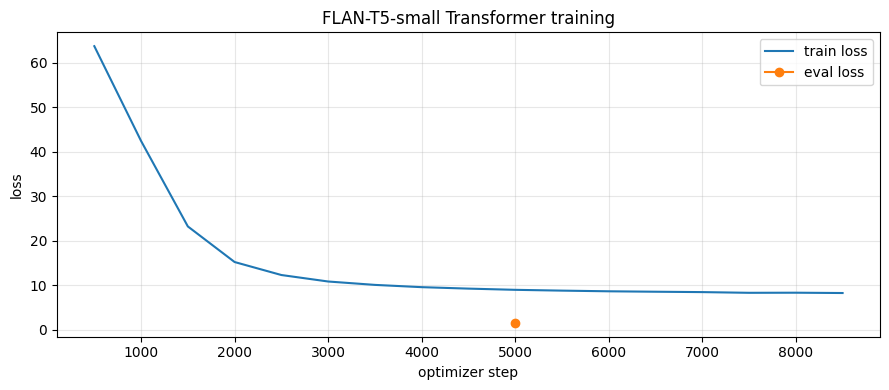

Saved: t5_trainer_log_history.json, 07_t5_training_curves.png


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved fine-tuned T5 to: /kaggle/working/t5_gec_best


In [23]:
# Model 4: fine-tune FLAN-T5-small for grammar correction
try:
    del model_lstm_noatt
except NameError:
    pass
try:
    del model_lstm_att
except NameError:
    pass
keras.backend.clear_session()
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

train = pd.read_parquet(OUT / "train.parquet")
val = pd.read_parquet(OUT / "val.parquet")

MODEL_NAME = "google/flan-t5-small"
PREFIX = "Correct the grammar in this sentence: "
MAX_INPUT_LEN = 128
MAX_TARGET_LEN = 128
VAL_N = len(val)
PER_DEVICE_BATCH = 16
GRAD_ACCUM = 4
EPOCHS = 1
SRC_DROPOUT_P = 0.05  # randomly drop ~5% of source words during training

train_t5 = train.reset_index(drop=True)
rng = np.random.default_rng(SEED)
val_t5 = val.iloc[rng.choice(len(val), VAL_N, replace=False)].reset_index(drop=True)

print(f"Fine-tuning {MODEL_NAME}")
print(f"Training pairs: {len(train_t5):,}")
print(f"Validation pairs: {len(val_t5):,}")
print(f"Source-word dropout: {SRC_DROPOUT_P}")

tokenizer_t5 = AutoTokenizer.from_pretrained(MODEL_NAME)
model_t5 = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

def _maybe_drop_words(text, p, rng):
    if p <= 0.0:
        return text
    words = str(text).split()
    if len(words) < 4:
        return text
    kept = [w for w in words if rng.random() > p]
    if not kept:
        return text
    return " ".join(kept)

class GECDataset(Dataset):
    def __init__(self, df, tokenizer, src_dropout_p=0.0, seed=SEED):
        self.src = df["src"].astype(str).tolist()
        self.tgt = df["tgt"].astype(str).tolist()
        self.tokenizer = tokenizer
        self.src_dropout_p = src_dropout_p
        self.rng = random.Random(seed)

    def __len__(self):
        return len(self.src)

    def __getitem__(self, idx):
        src = _maybe_drop_words(self.src[idx], self.src_dropout_p, self.rng)
        src = PREFIX + src
        model_inputs = self.tokenizer(src, max_length=MAX_INPUT_LEN, truncation=True)
        labels = self.tokenizer(text_target=self.tgt[idx], max_length=MAX_TARGET_LEN, truncation=True)
        model_inputs["labels"] = labels["input_ids"]
        return model_inputs

train_ds = GECDataset(train_t5, tokenizer_t5, src_dropout_p=SRC_DROPOUT_P, seed=SEED)
val_ds = GECDataset(val_t5, tokenizer_t5, src_dropout_p=0.0, seed=SEED + 1)
collator = DataCollatorForSeq2Seq(tokenizer=tokenizer_t5, model=model_t5, label_pad_token_id=-100)

steps_per_epoch = math.ceil(len(train_t5) / (PER_DEVICE_BATCH * GRAD_ACCUM))
total_steps = steps_per_epoch * EPOCHS
warmup_steps = max(1, int(total_steps * 0.06))
eval_save_steps = min(5000, max(1, total_steps // 3))
print(f"Approx optimizer steps: {total_steps:,} | warmup steps: {warmup_steps:,}")
print(f"Eval/save every {eval_save_steps:,} optimizer steps")

use_bf16 = torch.cuda.is_available() and getattr(torch.cuda, "is_bf16_supported", lambda: False)()
print(f"Precision: {'bf16' if use_bf16 else ('fp16' if torch.cuda.is_available() else 'fp32')}")

manifest_path = OUT / "t5_training_manifest.json"
manifest = {
    "notebook_version": NOTEBOOK_VERSION,
    "model_name": MODEL_NAME,
    "model_dir": "t5_gec_best",
    "completed": False,
    "started_utc": datetime.now(timezone.utc).isoformat(),
    "data_signature": data_signature(),
    "train_rows": int(len(train_t5)),
    "val_rows": int(len(val_t5)),
    "src_dropout_p": SRC_DROPOUT_P,
    "epochs": EPOCHS,
    "prefix": PREFIX,
}
save_json(manifest, manifest_path)

args_common = dict(
    output_dir=str(OUT / "t5_gec_checkpoints"),
    learning_rate=3e-4,
    per_device_train_batch_size=PER_DEVICE_BATCH,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=GRAD_ACCUM,
    num_train_epochs=EPOCHS,
    warmup_steps=warmup_steps,
    weight_decay=0.01,
    logging_steps=500,
    save_steps=eval_save_steps,
    eval_steps=eval_save_steps,
    save_total_limit=2,
    predict_with_generate=False,
    fp16=torch.cuda.is_available() and not use_bf16,
    bf16=use_bf16,
    report_to=[],
    seed=SEED,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

try:
    args = Seq2SeqTrainingArguments(evaluation_strategy="steps", save_strategy="steps", **args_common)
except TypeError:
    args = Seq2SeqTrainingArguments(eval_strategy="steps", save_strategy="steps", **args_common)

trainer = Seq2SeqTrainer(
    model=model_t5,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
)

t0 = time.time()
trainer.train()
print(f"T5 fine-tuning time: {(time.time() - t0) / 60:.1f} min")

log_history = trainer.state.log_history
save_json(log_history, OUT / "t5_trainer_log_history.json")
train_logs = [(x.get("step"), x.get("loss")) for x in log_history if "loss" in x and x.get("step") is not None]
eval_logs = [(x.get("step"), x.get("eval_loss")) for x in log_history if "eval_loss" in x and x.get("step") is not None]
if train_logs or eval_logs:
    plt.figure(figsize=(9, 4))
    if train_logs:
        xs, ys = zip(*train_logs)
        plt.plot(xs, ys, label="train loss")
    if eval_logs:
        xs, ys = zip(*eval_logs)
        plt.plot(xs, ys, marker="o", label="eval loss")
    plt.title("FLAN-T5-small Transformer training")
    plt.xlabel("optimizer step")
    plt.ylabel("loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUT / "07_t5_training_curves.png", dpi=120, bbox_inches="tight")
    plt.show()
print("Saved: t5_trainer_log_history.json, 07_t5_training_curves.png")

save_dir = OUT / manifest["model_dir"]
trainer.save_model(str(save_dir))
tokenizer_t5.save_pretrained(str(save_dir))

manifest.update({
    "completed": True,
    "finished_utc": datetime.now(timezone.utc).isoformat(),
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_metric": float(trainer.state.best_metric) if trainer.state.best_metric is not None else None,
})
save_json(manifest, manifest_path)
print(f"Saved fine-tuned T5 to: {save_dir}")


In [24]:
# Model 4 evaluation: FLAN-T5 generation metrics + iterative refinement

test = pd.read_parquet(OUT / "test.parquet")
manifest_path = OUT / "t5_training_manifest.json"
if not manifest_path.exists():
    raise FileNotFoundError("Run the T5 training cell first. This prevents old Transformer metrics from being reused.")

manifest = load_json(manifest_path)
if not manifest.get("completed"):
    raise RuntimeError("T5 training did not finish. Complete the training cell before evaluating.")
if manifest.get("data_signature") != data_signature():
    raise RuntimeError("The train/val/test files changed after T5 training. Re-run T5 training before evaluation.")

MODEL_DIR = OUT / manifest["model_dir"]
if not MODEL_DIR.exists():
    raise FileNotFoundError(f"Missing trained T5 directory: {MODEL_DIR}")

tokenizer_t5 = AutoTokenizer.from_pretrained(str(MODEL_DIR))
model_t5 = AutoModelForSeq2SeqLM.from_pretrained(str(MODEL_DIR))
device = "cuda" if torch.cuda.is_available() else "cpu"
model_t5.to(device)
model_t5.eval()
print(f"Loaded {MODEL_DIR} on {device}")

PREFIX = manifest.get("prefix", "Correct the grammar in this sentence: ")

GEN_KWARGS = dict(
    max_length=128,
    num_beams=5,
    length_penalty=0.7,
    no_repeat_ngram_size=3,
    early_stopping=True,
    min_length=1,
)

def t5_correct_batch(texts, batch_size=32):
    out = []
    for i in range(0, len(texts), batch_size):
        chunk = texts[i:i + batch_size]
        batch_src = [PREFIX + str(s) for s in chunk]
        inputs = tokenizer_t5(batch_src, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        with torch.no_grad():
            output_ids = model_t5.generate(**inputs, **GEN_KWARGS)
        out.extend(tokenizer_t5.batch_decode(output_ids, skip_special_tokens=True))
    return out

sample_idx = get_eval_sample_indices(len(test))
src_strs = test["src"].iloc[sample_idx].astype(str).tolist()
tgt_strs = test["tgt"].iloc[sample_idx].astype(str).tolist()

t0 = time.time()
pass1 = []
for i in tqdm(range(0, len(sample_idx), 32), desc="T5 pass 1"):
    pass1.extend(t5_correct_batch(src_strs[i:i + 32], batch_size=32))
print(f"Pass 1 generated in {time.time() - t0:.1f}s")

# Iterative refinement: re-run the model on its own pass-1 outputs. Accept the
# refinement only when it changes <= 3 tokens (stops cascading hallucinations).
t1 = time.time()
need = [i for i, p in enumerate(pass1) if p.strip() != src_strs[i].strip()]
pred_strs = list(pass1)
if need:
    refined = []
    for j in tqdm(range(0, len(need), 32), desc="T5 pass 2 (refine)"):
        batch_idx = need[j:j + 32]
        batch_texts = [pass1[k] for k in batch_idx]
        refined.extend(t5_correct_batch(batch_texts, batch_size=32))
    accepted = 0
    for k_pos, i_glob in enumerate(need):
        r = refined[k_pos]
        if token_edit(pass1[i_glob], r) <= 3:
            pred_strs[i_glob] = r
            if r != pass1[i_glob]:
                accepted += 1
    print(f"Pass 2 finished in {time.time() - t1:.1f}s | accepted refinements: {accepted}/{len(need)}")
else:
    print("No samples to refine (pass 1 returned source-identical for all).")

metrics_t5, examples_t5 = evaluate_predictions(
    "FLAN-T5-small Transformer",
    src_strs,
    tgt_strs,
    pred_strs,
    "t5_eval.json",
    "t5_examples.csv",
    sample_idx=sample_idx,
    extra={
        "model_dir": str(MODEL_DIR),
        "training_manifest": manifest,
        "generation_kwargs": GEN_KWARGS,
        "iterative_refinement": True,
    },
)


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Loaded /kaggle/working/t5_gec_best on cuda


T5 pass 1:   0%|          | 0/157 [00:00<?, ?it/s]

Pass 1 generated in 521.8s


T5 pass 2 (refine):   0%|          | 0/115 [00:00<?, ?it/s]

Pass 2 finished in 398.0s | accepted refinements: 290/3651
FLAN-T5-small Transformer on 5,000 test examples
GLEU=0.6359 | BLEU=0.6368 | exact=5.64% | helpful=37.6% | harm=35.4% | F0.5=32.55%
Behaviour (%):
category
harm         35.4
improved     32.0
unchanged    27.0
perfect       5.6
Saved: t5_eval.json, t5_examples.csv


## Final Results

,Model,Type,Val/Det Acc,GLEU,BLEU,Helpful%,Harm%,F0.5
0,BoW TF-IDF + LogReg,Detection,0.6286,NaN,NaN,NaN,NaN,0.628842
1,LSTM no-attention,Generation,NaN,0.174644,0.120561,3.12,95.76,0.028924
2,LSTM + Bahdanau attention + pointer-gen (greedy),Generation,NaN,0.616593,0.615220,14.42,12.80,0.156317
3,FLAN-T5-small Transformer,Generation,NaN,0.635937,0.636833,37.62,35.40,0.325462


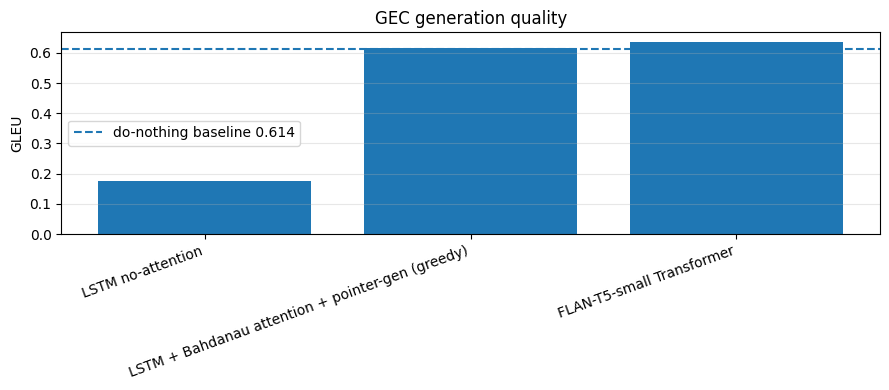

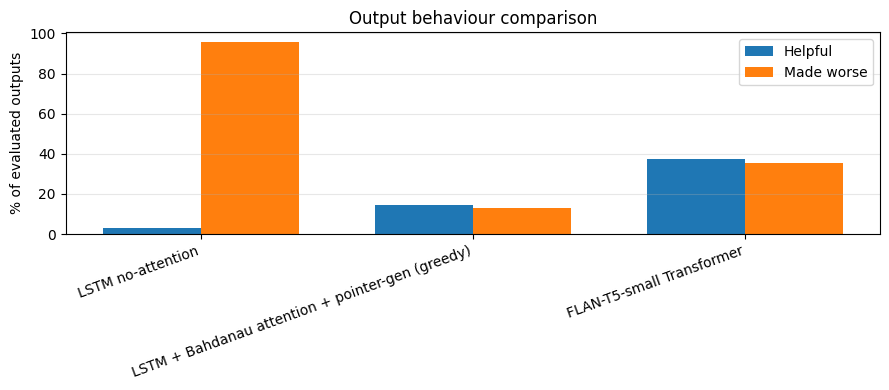

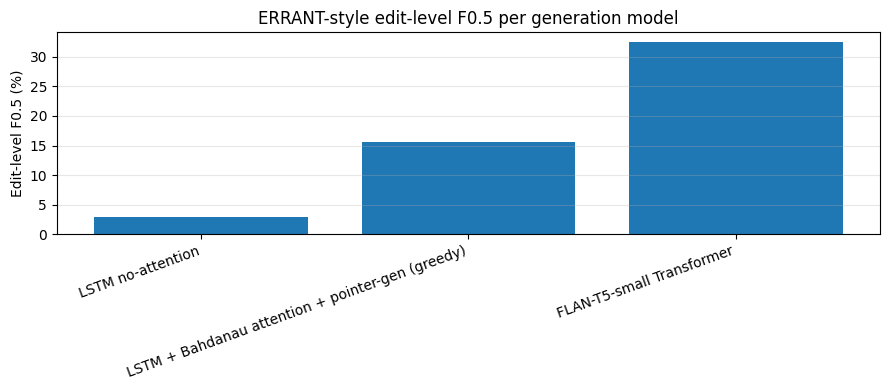

Saved: final_model_comparison.csv, 08_gleu_comparison.png, 09_helpful_harm_comparison.png, 10_f05_comparison.png


In [27]:
# Final comparison
def read_metric(name, expected_hash=None):
    path = OUT / name
    if not path.exists():
        print(f"Missing {name}; run the corresponding evaluation cell first.")
        return None
    metric = load_json(path)
    if expected_hash is not None and metric.get("sample_hash") != expected_hash:
        print(f"Skipping {name}; it was computed on a different evaluation sample.")
        return None
    return metric

test = pd.read_parquet(OUT / "test.parquet")
current_idx = get_eval_sample_indices(len(test))
current_hash = sample_hash(current_idx)

bow = read_metric("bow_metrics.json")
noatt = read_metric("lstm_noatt_eval.json", current_hash)
att = read_metric("lstm_att_eval.json", current_hash)
t5 = read_metric("t5_eval.json", current_hash)

rows = []
if bow:
    rows.append({
        "Model": "BoW TF-IDF + LogReg",
        "Type": "Detection",
        "Val/Det Acc": bow["val"]["acc"],
        "GLEU": np.nan,
        "BLEU": np.nan,
        "Helpful%": np.nan,
        "Harm%": np.nan,
        "F0.5": bow["val"].get("F05", np.nan),
    })
for metric in [noatt, att, t5]:
    if metric:
        rows.append({
            "Model": metric["model"],
            "Type": "Generation",
            "Val/Det Acc": np.nan,
            "GLEU": metric["gleu_pred"],
            "BLEU": metric["bleu_pred"],
            "Helpful%": metric["helpful_pct"],
            "Harm%": metric["harm_pct"],
            "F0.5": metric.get("f0.5_edit", np.nan),
        })

results = pd.DataFrame(rows)
if results.empty:
    raise RuntimeError("No metric files were loaded. Run the model evaluation cells first.")
display(results)
results.to_csv(OUT / "final_model_comparison.csv", index=False)

seq = results[results["Type"] == "Generation"].copy()
if len(seq) == 0:
    print("No generation metrics loaded yet; run the LSTM and T5 evaluation cells before drawing comparison charts.")
elif len(seq):
    plt.figure(figsize=(9, 4))
    plt.bar(seq["Model"], seq["GLEU"])
    baseline = next((m["gleu_src_baseline"] for m in [noatt, att, t5] if m and "gleu_src_baseline" in m), None)
    if baseline is not None:
        plt.axhline(baseline, linestyle="--", label=f"do-nothing baseline {baseline:.3f}")
        plt.legend()
    plt.ylabel("GLEU")
    plt.title("GEC generation quality")
    plt.xticks(rotation=20, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT / "08_gleu_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

    x = np.arange(len(seq))
    plt.figure(figsize=(9, 4))
    plt.bar(x - 0.18, seq["Helpful%"], width=0.36, label="Helpful")
    plt.bar(x + 0.18, seq["Harm%"], width=0.36, label="Made worse")
    plt.xticks(x, seq["Model"], rotation=20, ha="right")
    plt.ylabel("% of evaluated outputs")
    plt.title("Output behaviour comparison")
    plt.legend(); plt.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT / "09_helpful_harm_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

    if seq["F0.5"].notna().any():
        plt.figure(figsize=(9, 4))
        plt.bar(seq["Model"], seq["F0.5"].fillna(0.0) * 100)
        plt.ylabel("Edit-level F0.5 (%)")
        plt.title("ERRANT-style edit-level F0.5 per generation model")
        plt.xticks(rotation=20, ha="right")
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout(); plt.savefig(OUT / "10_f05_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

print("Saved: final_model_comparison.csv, 08_gleu_comparison.png, 09_helpful_harm_comparison.png, 10_f05_comparison.png")

## Grammar-Rule Analysis of Model Outputs

In [29]:
# Grammar-rule analysis for each model
def grammar_rule_label(src, tgt):
    s, t = str(src).strip(), str(tgt).strip()
    sl, tl = s.lower(), t.lower()
    if sl == tl and s != t:
        return "Capitalization"
    if re.sub(r"[.!?,;:]+$", "", s) == re.sub(r"[.!?,;:]+$", "", t) and s != t:
        return "Punctuation"
    if re.search(r"\b(\w+)\s+\1\b", s, flags=re.I) and not re.search(r"\b(\w+)\s+\1\b", t, flags=re.I):
        return "Repeated-word removal"
    if re.search(r"\b(a|an|the)\b", s, flags=re.I) != re.search(r"\b(a|an|the)\b", t, flags=re.I):
        return "Article or determiner"
    be = r"\b(is|are|was|were|am|be|been|being)\b"
    if re.search(be, s, flags=re.I) or re.search(be, t, flags=re.I):
        return "Verb agreement or be-verb"
    if len(s.split()) != len(t.split()):
        return "Insertion or deletion"
    return "Other grammar or style change"

def reasoning_for_output(src, tgt, pred):
    rule = grammar_rule_label(src, tgt)
    d_src = token_edit(src, tgt)
    d_pred = token_edit(pred, tgt)
    if str(pred).strip() == str(tgt).strip():
        outcome = "corrected the target exactly"
    elif str(pred).strip() == str(src).strip():
        outcome = "left the error unchanged"
    elif d_pred < d_src:
        outcome = "moved closer to the target but did not fully correct it"
    else:
        outcome = "made the sentence farther from the target"
    return f"Rule: {rule}. The model {outcome}."

def show_generation_examples(model_name, csv_name):
    path = OUT / csv_name
    if not path.exists():
        print(f"Missing {csv_name}; run the evaluation cell for {model_name} first.")
        return
    ex = pd.read_csv(path)
    print(f"\n{model_name}")
    for category in ["perfect", "improved", "unchanged", "harm"]:
        part = ex[ex["category"] == category].head(2)
        if part.empty:
            continue
        print(f"\n[{category}]")
        for _, row in part.iterrows():
            print(f"SRC: {row.src}")
            print(f"TGT: {row.tgt}")
            print(f"OUT: {row.pred}")
            print(reasoning_for_output(row.src, row.tgt, row.pred))

def show_bow_examples():
    vec_path = OUT / "bow_vec.joblib"
    clf_path = OUT / "bow_clf.joblib"
    if not vec_path.exists() or not clf_path.exists():
        print("Missing BoW saved files; run the BoW cell first.")
        return
    test = pd.read_parquet(OUT / "test.parquet")
    vec = joblib.load(vec_path)
    clf = joblib.load(clf_path)
    src_pred = clf.predict(vec.transform(test["src"].astype(str)))
    tgt_pred = clf.predict(vec.transform(test["tgt"].astype(str)))
    groups = {
        "successful detection": np.where((src_pred == 1) & (tgt_pred == 0))[0],
        "missed corruption": np.where(src_pred == 0)[0],
        "false alarm on clean target": np.where(tgt_pred == 1)[0],
    }
    print("\nBoW TF-IDF + Logistic Regression")
    for label, idxs in groups.items():
        print(f"\n[{label}]")
        for idx in idxs[:2]:
            src = test["src"].iloc[idx]
            tgt = test["tgt"].iloc[idx]
            print(f"SRC: {src}")
            print(f"TGT: {tgt}")
            print(f"Rule: {grammar_rule_label(src, tgt)}. BoW uses word and bigram counts, so it can flag surface patterns but cannot generate a corrected sentence or reliably model long-range syntax.")

show_bow_examples()
show_generation_examples("LSTM no-attention", "lstm_noatt_examples.csv")
show_generation_examples("LSTM + attention", "lstm_att_examples.csv")
show_generation_examples("T5-small Transformer", "t5_examples.csv")

# Link model outputs to dataset noise when noisy targets appear in evaluated examples.
def noise_reason_text(tgt):
    t = str(tgt)
    if re.search(r"\b(\w+)\s+\1\b", t, flags=re.I):
        return "target still has a repeated adjacent word"
    if len(t.split()) < 3:
        return "target is an extremely short fragment"
    if re.search(r"[{}<>|\\]{2,}", t):
        return "target contains markup or code-like noise"
    if t.count("?") + t.count("!") > 3:
        return "target contains excessive punctuation"
    if re.search(r"\s{2,}", t):
        return "target contains abnormal spacing"
    return ""

print("\nDataset-noise evidence inside evaluated model outputs")
shown = 0
for csv_name in ["lstm_noatt_examples.csv", "lstm_att_examples.csv", "t5_examples.csv"]:
    path = OUT / csv_name
    if not path.exists():
        continue
    ex = pd.read_csv(path)
    ex["noise_reason"] = ex["tgt"].apply(noise_reason_text)
    noisy = ex[ex["noise_reason"] != ""].head(2)
    if noisy.empty:
        continue
    print(f"\n{csv_name}")
    for _, row in noisy.iterrows():
        shown += 1
        print(f"Reason: {row.noise_reason}")
        print(f"SRC: {row.src}")
        print(f"TGT: {row.tgt}")
        print(f"OUT: {row.pred}")
if shown == 0:
    print("No obvious noisy targets appeared in the fixed evaluation sample. Use dataset_noise_examples.csv from the next cell for direct dataset evidence.")


BoW TF-IDF + Logistic Regression

[successful detection]
SRC: Buy to yours direct and save today.
TGT: Buy yours direct and save today.
Rule: Insertion or deletion. BoW uses word and bigram counts, so it can flag surface patterns but cannot generate a corrected sentence or reliably model long-range syntax.
SRC: Welcome in the modeling & Simulation forum!
TGT: Welcome to the Modeling & Simulation forum!
Rule: Article or determiner. BoW uses word and bigram counts, so it can flag surface patterns but cannot generate a corrected sentence or reliably model long-range syntax.

[missed corruption]
SRC: 08/21/2013 Motion referred to Budget and Finance Committee; economic Development Committee.
TGT: 08/21/2013 Motion referred to Budget and Finance Committee; Economic Development Committee.
Rule: Capitalization. BoW uses word and bigram counts, so it can flag surface patterns but cannot generate a corrected sentence or reliably model long-range syntax.
SRC: begin the 24 hour day?
TGT: begin th

## Dataset Noise and Rule Examples

In [30]:
# Final challenge support - grammar-rule examples and dataset-noise mining

test = pd.read_parquet(OUT/"test.parquet")

def simple_rule_label(src, tgt):
    s, t = str(src), str(tgt)
    if s.lower() == t.lower() and s != t:
        return "Capitalization"
    if re.sub(r"[.!?]+$", "", s) == re.sub(r"[.!?]+$", "", t) and s != t:
        return "Punctuation"
    if re.search(r"\b(\w+)\s+\1\b", s, flags=re.I) and not re.search(r"\b(\w+)\s+\1\b", t, flags=re.I):
        return "Repeated-word removal"
    if re.search(r"\b(a|an|the)\b", s, flags=re.I) != re.search(r"\b(a|an|the)\b", t, flags=re.I):
        return "Article/determiner change"
    if re.search(r"\b(is|are|was|were|am|be|been|being)\b", s, flags=re.I) or re.search(r"\b(is|are|was|were|am|be|been|being)\b", t, flags=re.I):
        return "Verb agreement / be-verb"
    if len(s.split()) != len(t.split()):
        return "Insertion/deletion"
    return "Other grammar/style change"

rule_df = test.sample(len(test), random_state=42).copy()
rule_df["rule_guess"] = [simple_rule_label(s, t) for s, t in zip(rule_df.src, rule_df.tgt)]
print("Rule-type sample counts:")
print(rule_df["rule_guess"].value_counts().to_string())

print("\nRepresentative source-target examples for report:")
for rule, group in rule_df.groupby("rule_guess"):
    print(f"\n[{rule}]")
    for _, r in group.head(2).iterrows():
        print(f"SRC: {r.src}\nTGT: {r.tgt}\n")

# Dataset noise: targets are not always perfect. These simple checks find evidence for the final-challenge discussion.
def noise_reason(tgt):
    t = str(tgt)
    if re.search(r"\b(\w+)\s+\1\b", t, flags=re.I):
        return "Target still has repeated adjacent word"
    if len(t.split()) < 3:
        return "Target is extremely short / likely fragment"
    if re.search(r"[{}<>|\\]{2,}", t):
        return "Target contains markup/code-like noise"
    if t.count("?") + t.count("!") > 3:
        return "Target contains excessive punctuation"
    if re.search(r"\s{2,}", t):
        return "Target contains abnormal spacing"
    return ""

noise = test.copy()
noise["noise_reason"] = noise["tgt"].apply(noise_reason)
noise = noise[noise["noise_reason"] != ""].head(100)
noise.to_csv(OUT/"dataset_noise_examples.csv", index=False)

print("\nPossible noisy target examples for the mandatory final challenge:")
for _, r in noise.head(5).iterrows():
    print(f"Reason: {r.noise_reason}\nSRC: {r.src}\nTGT: {r.tgt}\n")

print("Saved: dataset_noise_examples.csv")


Rule-type sample counts:
rule_guess
Article/determiner change     16836
Insertion/deletion             2815
Other grammar/style change     2436
Verb agreement / be-verb       2240
Repeated-word removal           286
Punctuation                     230
Capitalization                  157

Representative source-target examples for report:

[Article/determiner change]
SRC: INITIATIVES Review and approve for the sufficient answer form an initiative petition (version 1) submitted by Todd Jones for a proposed amendment of Article III of the Missouri Constitution.
TGT: INITIATIVES. Review and approval of the sufficiency as to form of an initiative petition (version 1) submitted by Todd Jones for a proposed amendment to Article III of the Missouri Constitution.

SRC: Exist the location as default and click Next.
TGT: Leave the location as default and click Next.


[Capitalization]
SRC: A simple example of a java class that can be shadowed.
TGT: A simple example of a Java class that can be shad

## Export Submission Files

In [31]:
# Export all PNGs and a PDF report into one ZIP file
EXPORT_DIR = OUT / "gec_project_export"
ZIP_PATH = OUT / "gec_project_export.zip"
PDF_PATH = EXPORT_DIR / "gec_project_results_report.pdf"
NOTEBOOK_PDF_PATH = EXPORT_DIR / "final_gec_project_notebook.pdf"

if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

patterns = ["*.png", "*.json", "*.csv"]
exported_files = []
for pattern in patterns:
    for path in sorted(OUT.glob(pattern)):
        if path.is_file() and path.name != ZIP_PATH.name:
            target = EXPORT_DIR / path.name
            shutil.copy2(path, target)
            exported_files.append(target)

png_files = sorted(EXPORT_DIR.glob("*.png"))
with PdfPages(PDF_PATH) as pdf:
    fig = plt.figure(figsize=(11, 8.5))
    fig.text(0.5, 0.92, "Grammar Error Correction Project", ha="center", fontsize=20, weight="bold")
    fig.text(0.5, 0.86, "Saved figures, metrics, and qualitative artifacts", ha="center", fontsize=12)
    summary_lines = [
        f"Export created: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
        f"PNG figures: {len(png_files)}",
        f"Artifacts copied: {len(exported_files)}",
    ]
    metrics_path = EXPORT_DIR / "final_model_comparison.csv"
    if metrics_path.exists():
        summary_lines.append("Final comparison table: included")
    fig.text(0.08, 0.72, "\n".join(summary_lines), fontsize=12, va="top")
    plt.axis("off")
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    if metrics_path.exists():
        table = pd.read_csv(metrics_path)
        fig, ax = plt.subplots(figsize=(11, 8.5))
        ax.axis("off")
        ax.set_title("Final Model Comparison", fontsize=16, weight="bold", pad=20)
        shown = table.copy()
        for col in shown.columns:
            if shown[col].dtype.kind in "fc":
                shown[col] = shown[col].map(lambda x: "" if pd.isna(x) else f"{x:.4f}")
        tbl = ax.table(cellText=shown.values, colLabels=shown.columns, loc="center", cellLoc="center")
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(8)
        tbl.scale(1, 1.4)
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    for path in png_files:
        img = plt.imread(path)
        fig, ax = plt.subplots(figsize=(11, 8.5))
        ax.imshow(img)
        ax.set_title(path.name, fontsize=12, pad=10)
        ax.axis("off")
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

exported_files.append(PDF_PATH)
print(f"Saved PDF report: {PDF_PATH}")

ipynb_candidates = []
for root in [OUT, Path("/kaggle/input")]:
    if root.exists():
        ipynb_candidates.extend(sorted(root.rglob("*.ipynb")))

converted_notebook_pdf = False
if ipynb_candidates:
    notebook_source = ipynb_candidates[0]
    try:
        subprocess.run(
            [sys.executable, "-m", "jupyter", "nbconvert", "--to", "pdf", "--output", str(NOTEBOOK_PDF_PATH.with_suffix('').name), str(notebook_source)],
            cwd=str(EXPORT_DIR),
            check=True,
            capture_output=True,
            text=True,
            timeout=180,
        )
        converted_notebook_pdf = NOTEBOOK_PDF_PATH.exists()
        if converted_notebook_pdf:
            exported_files.append(NOTEBOOK_PDF_PATH)
            print(f"Saved notebook PDF: {NOTEBOOK_PDF_PATH}")
    except Exception as exc:
        print(f"Notebook-to-PDF conversion skipped: {exc}")
else:
    print("No .ipynb file found for notebook-to-PDF conversion. PDF report was created instead.")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(EXPORT_DIR.rglob("*")):
        if path.is_file():
            zf.write(path, arcname=path.relative_to(EXPORT_DIR))

print(f"Export folder: {EXPORT_DIR}")
print(f"ZIP file: {ZIP_PATH}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / 1e6:.2f} MB")
print(f"Notebook PDF included: {converted_notebook_pdf}")
display(FileLink(str(ZIP_PATH)))

Saved PDF report: /kaggle/working/gec_project_export/gec_project_results_report.pdf
Notebook-to-PDF conversion skipped: Command '['/usr/bin/python3', '-m', 'jupyter', 'nbconvert', '--to', 'pdf', '--output', 'final_gec_project_notebook', '/kaggle/working/.virtual_documents/__notebook_source__.ipynb']' returned non-zero exit status 1.
Export folder: /kaggle/working/gec_project_export
ZIP file: /kaggle/working/gec_project_export.zip
ZIP size: 2.29 MB
Notebook PDF included: False


/kaggle/working/gec_project_export.zip